<a href="https://colab.research.google.com/github/zoedelblum/L02-hedonic-pricing/blob/main/notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Hedonic Pricing

We often try to predict the price of an asset from its observable characteristics. This is generally called **hedonic pricing**: How do the unit's characteristics determine its market price?

1. Clean the data `pierce_county_house_sales.csv` and perform some EDA and visualization to get to know the data set.
2. Transform your variables - particularly categorical ones - for use in your regression analysis.
3. Implement an 80/20 train-test split. Put the test data aside.
4. Build some simple linear models that include no transformations or interactions. Fit them, and determine their RMSE and $R^2$ on the both the training and test sets. Which of your models does the best?
5. Make partial correlation plots for each of the numeric variables in your model. Do you notice any significant non-linearities?
6. Include transformations and interactions of your variables, and build a more complex model that reflects your ideas about how the features of the asset determine its value. Determine its RMSE and $R^2$ on the training and test sets. How does the more complex model your build compare to the simpler ones?
7. Summarize your results from 1 to 6. Have you learned anything about overfitting and underfitting, or model selection?
8. Use the `sklearn.linear_model.Lasso` to regularize your model and select the most predictive features. Which does it select? What are the RMSE and $R^2$? We'll cover the Lasso later in detail in class.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Zoe Edelblum, Evie McMahan, Aurea McIntosh

**Date:** 11/9

## 1. Clean the data `pierce_county_house_sales.csv` and perform some EDA and visualization to get to know the data set.

In [17]:
# Your Phase 1 solution to the problem goes here.
#!pip install pandas
#!pip install numpy
#!pip install matplotlib
#!pip install seaborn
#!pip install statsmodels
#!pip install scikit-learn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.nonparametric.smoothers_lowess import lowess
from sklearn.model_selection import train_test_split

In [18]:
pierce_country_house_sales = pd.read_csv('pierce_county_house_sales.csv')
pierce_country_house_sales.head()

,sale_date,sale_price,house_square_feet,attic_finished_square_feet,basement_square_feet,attached_garage_square_feet,detached_garage_square_feet,fireplaces,hvac_description,exterior,interior,stories,roof_cover,year_built,bedrooms,bathrooms,waterfront_type,view_quality,utility_sewer
0,2020-01-02,380000,2157,0,0,528,0,0,Warm and Cool Air Zone,Frame Siding,Drywall,2,Composition Shingle,1993,3,3,NaN,NaN,SEWER/SEPTIC INSTALLED
1,2020-01-02,383000,2238,0,0,396,0,0,Forced Air,Frame Siding,Drywall,2,Composition Shingle,2017,4,3,NaN,NaN,SEWER/SEPTIC INSTALLED
2,2020-01-01,419900,1452,0,0,0,0,1,Forced Air,Frame Siding,Drywall,1,Built Up Rock,1965,3,2,NaN,NaN,SEWER/SEPTIC INSTALLED
3,2020-01-02,251660,832,0,0,0,0,0,Forced Air,Frame Vinyl,Drywall,1,Composition Shingle,1919,2,1,NaN,NaN,SEWER/SEPTIC INSTALLED
4,2020-01-02,500000,1780,0,384,484,0,1,Forced Air,Frame Siding,Drywall,1,Composition Shingle,1955,3,2,NaN,NaN,SEWER/SEPTIC INSTALLED


In [19]:
pierce_country_house_sales.describe()

,sale_price,house_square_feet,attic_finished_square_feet,basement_square_feet,attached_garage_square_feet,detached_garage_square_feet,fireplaces,stories,year_built,bedrooms,bathrooms
count,1.681400e+04,16814.000000,16814.000000,16814.000000,16814.000000,16814.000000,16814.000000,16814.000000,16814.000000,16814.000000,16814.000000
mean,4.612332e+05,1879.941953,24.945878,167.852861,364.425122,38.298501,0.889021,1.558285,1980.469252,3.277983,2.317176
std,2.360833e+05,760.419008,102.066417,429.065832,286.454018,164.691471,0.596731,0.512055,33.339025,0.891240,0.827956
min,2.000000e+03,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1880.000000,0.000000,0.000000
25%,3.480000e+05,1320.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1959.000000,3.000000,2.000000
50%,4.165000e+05,1774.000000,0.000000,0.000000,420.000000,0.000000,1.000000,2.000000,1990.000000,3.000000,2.000000
75%,5.238065e+05,2352.000000,0.000000,0.000000,528.000000,0.000000,1.000000,2.000000,2006.000000,4.000000,3.000000
max,6.130000e+06,9510.000000,1212.000000,4000.000000,2816.000000,3664.000000,5.000000,3.000000,2021.000000,25.000000,8.000000


In [20]:
pierce_country_house_sales.info()
pierce_country_house_sales.isna().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16814 entries, 0 to 16813
Data columns (total 19 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   sale_date                    16814 non-null  object
 1   sale_price                   16814 non-null  int64 
 2   house_square_feet            16814 non-null  int64 
 3   attic_finished_square_feet   16814 non-null  int64 
 4   basement_square_feet         16814 non-null  int64 
 5   attached_garage_square_feet  16814 non-null  int64 
 6   detached_garage_square_feet  16814 non-null  int64 
 7   fireplaces                   16814 non-null  int64 
 8   hvac_description             16807 non-null  object
 9   exterior                     16813 non-null  object
 10  interior                     16807 non-null  object
 11  stories                      16814 non-null  int64 
 12  roof_cover                   16806 non-null  object
 13  year_built                   16

,0
sale_date,0
sale_price,0
house_square_feet,0
attic_finished_square_feet,0
basement_square_feet,0
attached_garage_square_feet,0
detached_garage_square_feet,0
fireplaces,0
hvac_description,7
exterior,1


Most of the other variables have no mising values with a few having 8 or less missing values. This output describes that `waterfront_type` and `view_quality` have around 15,000 - 16,000 missing values.

In [21]:
pierce_country_house_sales['hvac_description'].unique()
pierce_country_house_sales.loc[pierce_country_house_sales['hvac_description'] == 'Floor Wall Furnace', 'hvac_description', ] = 'Floor/Wall Furnace'
pierce_country_house_sales.loc[pierce_country_house_sales['hvac_description'] == 'Electric', 'hvac_description', ] = 'Electric Baseboard'
pierce_country_house_sales['hvac_description'].unique()

array(['Warm and Cool Air Zone', 'Forced Air', 'Electric Baseboard',
       'Heat Pump', 'Floor/Wall Furnace', 'No Heat',
       'Hot Water Baseboard', nan], dtype=object)

In the hvac_description column of the dataframe, there were two repeats with slightly different names. We standardized these names for the Floor/Wall Furnace and the Electric baseboard.

In [22]:
print(pierce_country_house_sales['exterior'].unique())
print(pierce_country_house_sales['interior'].unique())
print(pierce_country_house_sales['roof_cover'].unique())
print(pierce_country_house_sales['utility_sewer'].unique())

['Frame Siding' 'Frame Vinyl' 'Masonry Concrete Block'
 'Masonry Common Brick' 'Frame Stucco' 'Finished Cottage'
 'Frame Hardboard' 'Frame Rustic Log' 'Log' 'Unfinished Cottage'
 'Pine Finished Cabin' 'Cedar Finished Cabin' nan 'Cedar A-Frame'
 'Pine A-Frame' 'Cedar Unfinished Cabin' 'Pine Unfinished Cabin']
['Drywall' nan 'Paneling']
['Composition Shingle' 'Built Up Rock' 'Wood Shake' 'Concrete Tile'
 'Preformed Metal' 'Formed Seam Metal' nan]
['SEWER/SEPTIC INSTALLED' 'SEWER AVAILABLE' 'SEWER/SEPTIC NO'
 'SEWER/SEPTIC NO PERC' 'SEWER/SEPTIC AVAIL']


Examined whether there were repeats of labeling in different formats, but `exterior`, `interior`, `roof_cover`, and `utility_sewer` didn't have repeats issues with inconsistent formatting.

In [23]:
duplicate_rows = pierce_country_house_sales[pierce_country_house_sales.duplicated(keep=False)]
print(duplicate_rows)
pierce_country_house_sales_no_dups = pierce_country_house_sales.drop_duplicates()
print(pierce_country_house_sales_no_dups[pierce_country_house_sales_no_dups.duplicated(keep=False)])

        sale_date  sale_price  house_square_feet  attic_finished_square_feet  \
148    2020-01-07      364900               1676                           0   
214    2020-01-07      367900               1676                           0   
533    2020-01-07      366900               1482                           0   
549    2020-01-07      364900               1676                           0   
550    2020-01-07      400900               2224                           0   
...           ...         ...                ...                         ...   
15207  2020-01-28      145500               1420                           0   
15966  2020-12-03      376500               1830                           0   
15973  2020-12-03      376500               1830                           0   
15975  2020-12-17     1360000               3128                           0   
15976  2020-12-17     1360000               3128                           0   

       basement_square_feet  attached_g

Looked at full row duplicates to confirm they were valid before dropping them.

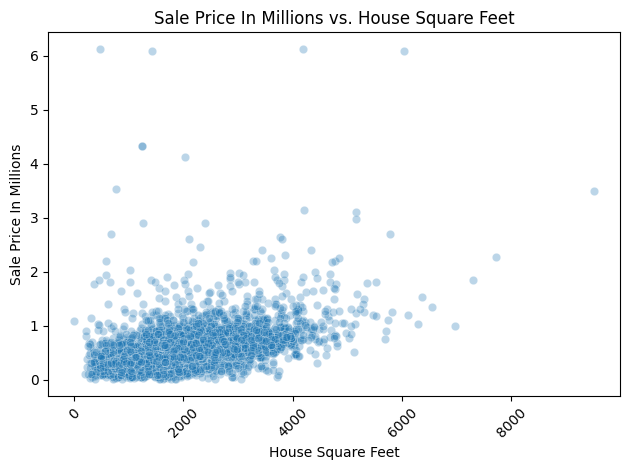

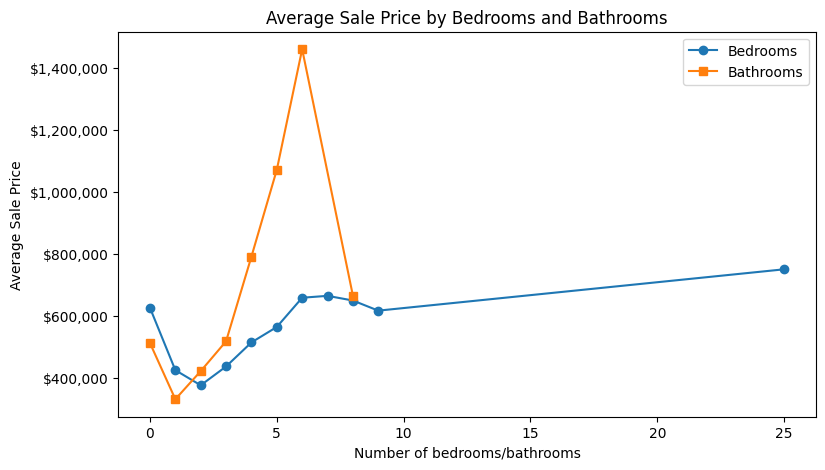

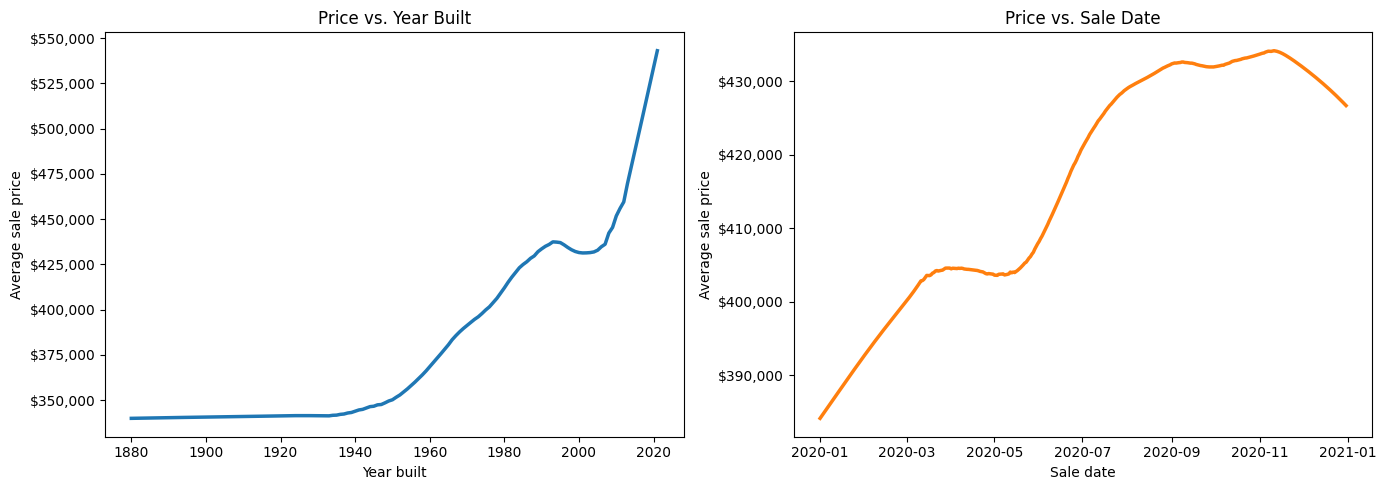

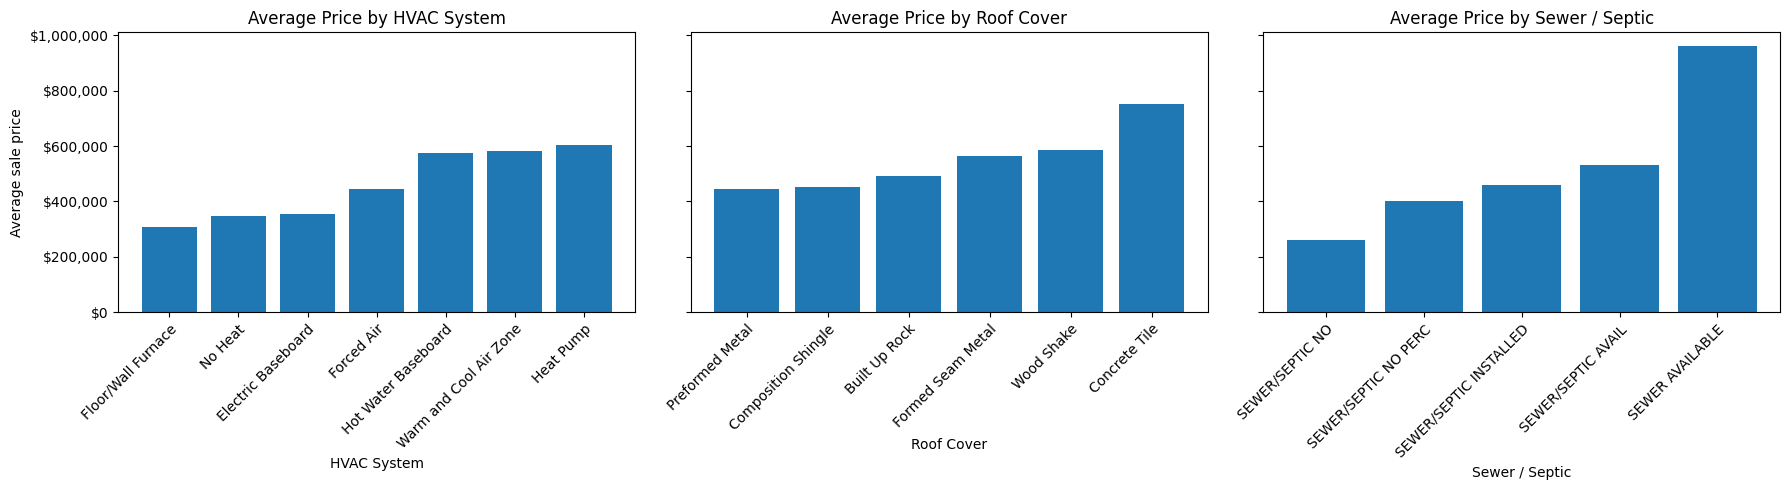

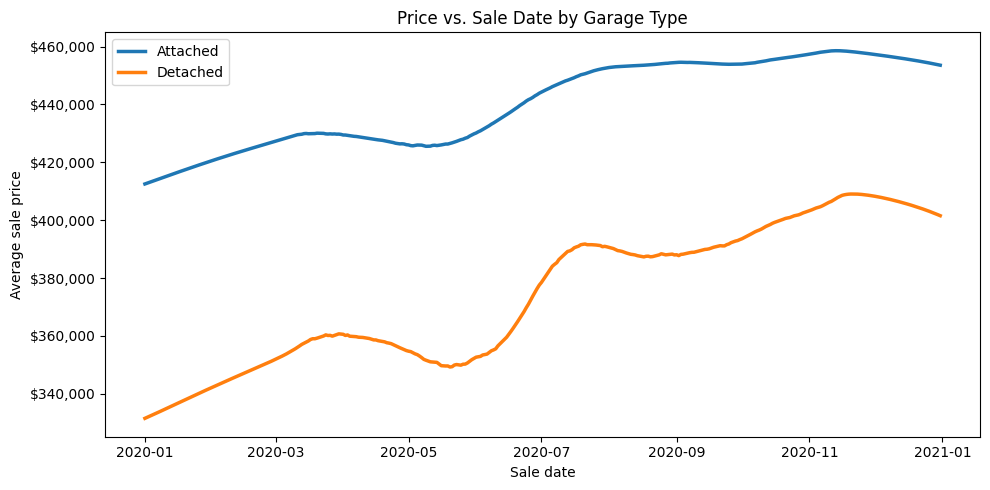

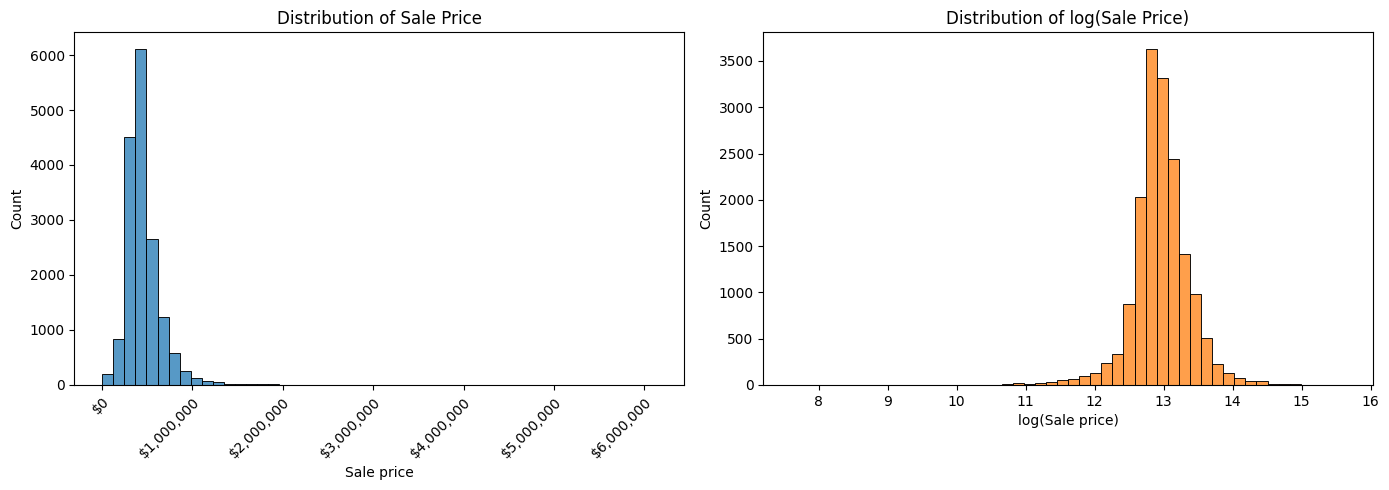

Skewness (raw): 6.5
Skewness (log): -0.84


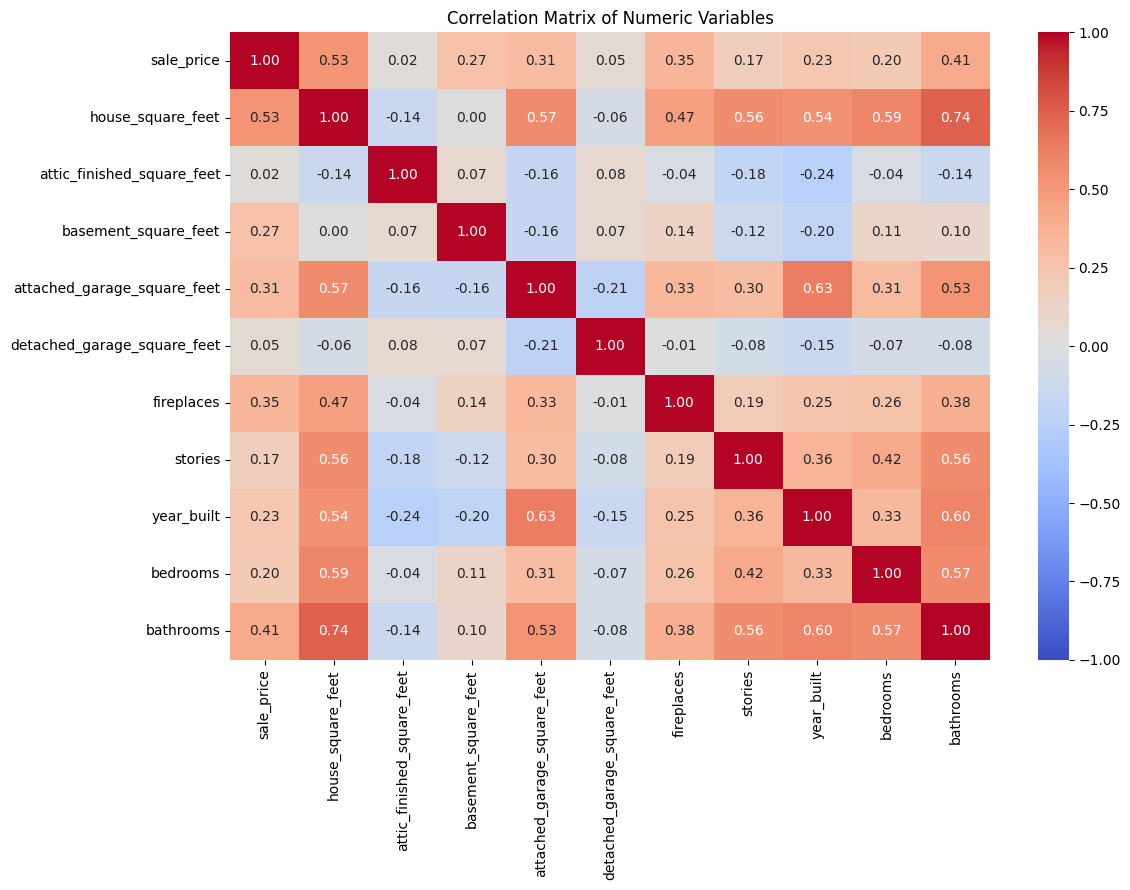

house_square_feet              0.525828
bathrooms                      0.409170
fireplaces                     0.347678
attached_garage_square_feet    0.310396
basement_square_feet           0.270301
year_built                     0.228875
bedrooms                       0.204819
stories                        0.166498
detached_garage_square_feet    0.051994
attic_finished_square_feet     0.021623
Name: sale_price, dtype: float64


In [24]:
clean = pierce_country_house_sales_no_dups.copy()
clean = clean.dropna(subset=['sale_price', 'year_built', 'sale_date'])

#Sqft versus price
sns.scatterplot(data=clean, x='house_square_feet', y='sale_price', alpha=0.3)
plt.xlabel('House Square Feet')
plt.ylabel('Sale Price In Millions')
plt.title('Sale Price In Millions vs. House Square Feet')
plt.gca().yaxis.set_major_formatter(lambda x, pos: f'{x / 1e6:g}')
plt.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

#Bedrooms and bathrooms versus price
bed_avg = clean.groupby('bedrooms')['sale_price'].mean()
bath_avg = clean.groupby('bathrooms')['sale_price'].mean()

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(bed_avg.index, bed_avg.values, marker='o', label='Bedrooms')
ax.plot(bath_avg.index, bath_avg.values, marker='s', label='Bathrooms')
ax.set_xlabel('Number of bedrooms/bathrooms')
ax.set_ylabel('Average Sale Price')
ax.set_title('Average Sale Price by Bedrooms and Bathrooms')
ax.yaxis.set_major_formatter('${x:,.0f}')
ax.legend()
plt.show()

clean['sale_date'] = pd.to_datetime(clean['sale_date'])
sale_num = clean['sale_date'].map(pd.Timestamp.toordinal)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

#Price versus year built
fit = lowess(clean['sale_price'], clean['year_built'], frac=0.3)
ax1.plot(fit[:, 0], fit[:, 1], color='tab:blue', linewidth=2.5)
ax1.set_xlabel('Year built')
ax1.set_ylabel('Average sale price')
ax1.set_title('Price vs. Year Built')
ax1.yaxis.set_major_formatter('${x:,.0f}')

#Price versus sale date
fit = lowess(clean['sale_price'], sale_num, frac=0.3)
ax2.plot([pd.Timestamp.fromordinal(int(x)) for x in fit[:, 0]], fit[:, 1], color='tab:orange', linewidth=2.5)
ax2.set_xlabel('Sale date')
ax2.set_ylabel('Average sale price')
ax2.set_title('Price vs. Sale Date')
ax2.yaxis.set_major_formatter('${x:,.0f}')

plt.tight_layout()
plt.show()

#Hvac system, roof cover, and sewer/septic versus price
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

for ax, col, title in zip(axes, ['hvac_description', 'roof_cover', 'utility_sewer'], ['HVAC System', 'Roof Cover', 'Sewer / Septic']):
    avg = clean.groupby(col)['sale_price'].mean().sort_values()
    ax.bar(avg.index.astype(str), avg.values)
    ax.set_title(f'Average Price by {title}')
    ax.set_xlabel(title)
    plt.setp(ax.get_xticklabels(), rotation=45, ha='right', rotation_mode='anchor')

axes[0].set_ylabel('Average sale price')
axes[0].yaxis.set_major_formatter('${x:,.0f}')

plt.tight_layout()
plt.show()

#Attatched versus detatched garage with price and sale date
attatched = clean['attached_garage_square_feet'].fillna(0) > 0
detatched = clean['detached_garage_square_feet'].fillna(0) > 0
clean['garage_type'] = np.select([attatched & ~detatched, detatched & ~attatched], ['Attached', 'Detached'], default=None)
g = clean.dropna(subset=['garage_type', 'sale_price', 'sale_date'])
g_num = g['sale_date'].map(pd.Timestamp.toordinal)

fig, ax = plt.subplots(figsize=(10, 5))

for label, color in [('Attached', 'tab:blue'), ('Detached', 'tab:orange')]:
    mask = g['garage_type'] == label
    fit = lowess(g.loc[mask, 'sale_price'], g_num[mask], frac=0.3)
    ax.plot([pd.Timestamp.fromordinal(int(x)) for x in fit[:, 0]], fit[:, 1],
            color=color, linewidth=2.5, label=label)

ax.set_xlabel('Sale date')
ax.set_ylabel('Average sale price')
ax.set_title('Price vs. Sale Date by Garage Type')
ax.yaxis.set_major_formatter('${x:,.0f}')
ax.legend()
plt.tight_layout()
plt.show()

#Raw versus log sale price distribution
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(clean['sale_price'], bins=50, ax=ax1)
ax1.set_xlabel('Sale price')
ax1.set_title('Distribution of Sale Price')
ax1.xaxis.set_major_formatter('${x:,.0f}')
plt.setp(ax1.get_xticklabels(), rotation=45, ha='right', rotation_mode='anchor')

sns.histplot(np.log(clean['sale_price']), bins=50, ax=ax2, color='tab:orange')
ax2.set_xlabel('log(Sale price)')
ax2.set_title('Distribution of log(Sale Price)')

plt.tight_layout()
plt.show()

print('Skewness (raw):', clean['sale_price'].skew().round(2))
print('Skewness (log):', np.log(clean['sale_price']).skew().round(2))

#Correlation matrix
num = clean.select_dtypes('number')
corr = num.corr()

plt.figure(figsize=(12, 9))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1)
plt.title('Correlation Matrix of Numeric Variables')
plt.tight_layout()
plt.show()

#Strongest correlations with price
print(corr['sale_price'].drop('sale_price').sort_values(key=abs, ascending=False).head(10))

`house_square_feet` versus `sale_price` plot shows most houses sold between 0 and 1 Million dollars. As the house square footage increases above 3,000, there appears to be a slight increase in baseline price.

The average sale price appears to exponentially grow from 1 bathrooms to 6 bathrooms, but the average price significantly decreases as we go from 6 to 7 bathrooms. The average price increases from 2 bedrooms to 6 bedrooms at a relatively stable rate. Then, there is a slightly increasing slope from 10 to 25 bedrooms. The increase in the average price is also much larger for the bathrooms than the bedrooms.

The average sale price is constant for houses built from 1880 to 1940, followed by an increase from houses built in 1940 to ~1995, a minor dip for 10 years, and a steaper increase from ~2005 to 2021.

However, the average sale price based on time of year in 2020 starts off low and increasing from January to March. The average sale price then stays about the same from March to May, followed by a similarly slopped increase from May to September. There isn't much change in the average sale price from September to November. Then, there is a slight decrease from November to January of 2021.

When looking at the average sale price differences between types of HVAC systems, types of roof cover, and whether sewer or septic is installed or available, it is clear that there is a significant difference in price when sewer is available for installation versus sewer and/or septic are available for installation. The roof cover distribution describes that concrete tile is the highest average price. In terms of the HVAC system, there isn't much of a price difference between floor/wall furnace, no heat, and electric baseboard. Forced air is slightly higher in average price than floor/wall furnace, no heat, and electric baseboard, and hot water baseboard, warm and cool air zone, and heat pump all have an even higher average price than the previously mentioned HVAC systems.

The average price of a house with an attatched versus detatched garage follow the same general curve. The attatched garage starts at about 100,000 more expensive on average than the detatched garage, but this difference decreases later in the year to about 60,000 more expensive on average.

The raw sale prices are right-skewed (skewness of 6.5). Most homes sell between roughly 250,000 and 600,000, with a long tail of expensive sales out to about 2.25 million with an outlier at 6 million. Taking the log pulls the distribution into a roughly bell shape centered near 13 (~440,000), with a skew of -0.84. The remaining skew is a very short left tail of very cheap sales. This supports using log(sale_price) as the regression target.

The correlation matrix shows that house size and amenities have the strongest relationships with sale price. House square footage has the highest correlation with price, followed by bathrooms, fireplaces, and attached garage size. This suggests that larger, better-equipped homes sell for more. In contrast, finished attic square footage and detached garage square footage have almost no linear relationship with price, while year built and bedrooms are only modestly related. Several predictors are also strongly correlated with each other. Square footage and bathrooms have a correlation of 0.74, and square footage is also related to bedrooms, stories, and year built, while year built and attached garage size correlate at 0.63. This overlap suggests multicollinearity could be a concern in the regression, as the model may struggle to separate the individual effect of each of these variables on price.

## 2. Transform your variables - particularly categorical ones - for use in your regression analysis.

In [25]:
transform = pierce_country_house_sales_no_dups.copy()
transform['sale_date'] = pd.to_datetime(transform['sale_date'])
transform = transform.dropna(subset=['sale_price', 'year_built', 'sale_date'])

#Missing values mean the feature is absent
for col in ['waterfront_type', 'view_quality']:
    transform[col] = transform[col].fillna('None')
for col in ['attached_garage_square_feet', 'detached_garage_square_feet']:
    transform[col] = transform[col].fillna(0)

#Target is log transform
transform['log_price'] = np.log(transform['sale_price'])

#Numeric features from dates
transform['sale_year'] = transform['sale_date'].dt.year
transform['sale_month'] = transform['sale_date'].dt.month
transform['house_age'] = transform['sale_year'] - transform['year_built']

#Garage flags (replaces the plotting-only garage_type column)
transform['has_attached_garage'] = (transform['attached_garage_square_feet'] > 0).astype(int)
transform['has_detached_garage'] = (transform['detached_garage_square_feet'] > 0).astype(int)
transform = transform.drop(columns=['garage_type'], errors='ignore')

#Ordinal categoricals map to integers if they have a natural order
view_order = {'None': 0, 'View Lim -': 1, 'View Lim': 2, 'View Lim +': 3, 'View Avg': 4, 'View Avg +': 5, 'View Good': 6, 'View Good +': 7, 'View V-Good': 8, }
transform['view_quality'] = transform['view_quality'].map(view_order)

#Group rare levels into 'Other'
nominal_cols = ['hvac_description', 'exterior', 'interior', 'roof_cover', 'utility_sewer', 'waterfront_type']
for col in nominal_cols:
    counts = transform[col].value_counts()
    rare = counts[counts < 30].index
    transform[col] = transform[col].where(~transform[col].isin(rare), 'Other')

num_cols = transform.select_dtypes(include='number').columns.tolist() # List of numerical columns

transform_encoded = pd.get_dummies(transform, columns=nominal_cols, drop_first=True, dtype=int)

#Drop columns that can't be used as features
transform_encoded = transform_encoded.drop(columns=['sale_date'])

#Check
print(num_cols)
print(transform_encoded.dtypes.value_counts())
print(transform_encoded.select_dtypes(exclude='number').columns.tolist())
print(transform_encoded.isna().sum()[lambda s: s > 0])

['sale_price', 'house_square_feet', 'attic_finished_square_feet', 'basement_square_feet', 'attached_garage_square_feet', 'detached_garage_square_feet', 'fireplaces', 'stories', 'year_built', 'bedrooms', 'bathrooms', 'view_quality', 'log_price', 'sale_year', 'sale_month', 'house_age', 'has_attached_garage', 'has_detached_garage']
int64      38
int32       2
float64     1
Name: count, dtype: int64
[]
Series([], dtype: int64)


We cleaned our data by parsing `sale_date` as a datetime, dropping rows that were missing the feature, and filling missing values. We then transformed the `sale_price` using the log scale since the distribution of price was right-skewed. We then transformed our feature variables, encoded categorical variables, and did a few final checks that showed all of our columns are now numeric. We also split into categorical and numerical columns before encoding categorical variables, so we can use different groupings of feature variables for our linear model.

## 3. Implement an 80/20 train-test split. Put the test data aside.

In [26]:
X = transform_encoded.drop(columns=['sale_price', 'log_price']) # Feature variables, not included the target
y = transform_encoded['sale_price'] # Don't use transformations for now

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42) # 80/20 split

print('Train:', X_train.shape, ' Test:', X_test.shape)

Train: (13414, 39)  Test: (3354, 39)


After implementing an 80/20 train-test split, our training dataset is 13,414 rows by 39 columns, and our testing dataset is 3,354 rows by 39 columns.

## 4. Build some simple linear models that include no transformations or interactions. Fit them, and determine their RMSE and $R^2$ on the both the training and test sets. Which of your models does the best?

In [27]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

# Model #1 (original numerical variables only)
num_features = [c for c in num_cols if c not in ['sale_price', 'log_price']] # Remove target from num_cols
sk_fit_num = LinearRegression().fit(X_train[num_features], y_train) # Fit model

y_num_train_pred = sk_fit_num.predict(X_train[num_features]) # Predict y on training set
y_num_test_pred = sk_fit_num.predict(X_test[num_features]) # Predict y on test set

print("Linear model using numerical feature variables:")
print("Training set R-squared:", round(sk_fit_num.score(X_train[num_features], y_train), 4))
print("Training set RMSE:", round(np.sqrt(mean_squared_error(y_train, y_num_train_pred)), 2))

print("Test set R-squared:", round(sk_fit_num.score(X_test[num_features], y_test), 4))
print("Test set RMSE:", round(np.sqrt(mean_squared_error(y_test, y_num_test_pred)), 2))


Linear model using numerical feature variables:
Training set R-squared: 0.4239
Training set RMSE: 181781.99
Test set R-squared: 0.4376
Test set RMSE: 166504.35


In [28]:
# Model #2 (original categorical variables only)
cat_features = [c for c in X_train.columns if c not in num_cols]
sk_fit_cat = LinearRegression().fit(X_train[cat_features], y_train) # Fit model

y_cat_train_pred = sk_fit_cat.predict(X_train[cat_features]) # Predict y on training set
y_cat_test_pred = sk_fit_cat.predict(X_test[cat_features]) # Predict y on test set

print("Linear model using categorical feature variables:")
print("Training set R-squared:", round(sk_fit_cat.score(X_train[cat_features], y_train), 4))
print("Training set RMSE:", round(np.sqrt(mean_squared_error(y_train, y_cat_train_pred)), 2))

print("Test set R-squared:", round(sk_fit_cat.score(X_test[cat_features], y_test), 4))
print("Test set RMSE:", round(np.sqrt(mean_squared_error(y_test, y_cat_test_pred)), 2))


Linear model using categorical feature variables:
Training set R-squared: 0.2757
Training set RMSE: 203828.08
Test set R-squared: 0.2692
Test set RMSE: 189801.33


In [29]:
# Model #3 (all feature variables)
all_features = num_features + cat_features # Bring together cat and num features

sk_fit_all = LinearRegression().fit(X_train[all_features], y_train) # Fit model

y_all_train_pred = sk_fit_all.predict(X_train[all_features]) # Predict y on training set
y_all_test_pred = sk_fit_all.predict(X_test[all_features]) # Predict y on test set

print("Linear model using all feature variables:")
print("Training set R-squared:", round(sk_fit_all.score(X_train[all_features], y_train), 4))
print("Training set RMSE:", round(np.sqrt(mean_squared_error(y_train, y_all_train_pred)), 2))

print("Test set R-squared:", round(sk_fit_all.score(X_test[all_features], y_test), 4))
print("Test set RMSE:", round(np.sqrt(mean_squared_error(y_test, y_all_test_pred)), 2))


Linear model using all feature variables:
Training set R-squared: 0.5341
Training set RMSE: 163479.53
Test set R-squared: 0.5424
Test set RMSE: 150194.77


The model using all feature variables best predicts sale price. It has the highest test set r-squared compared to the other models of 0.54 (numeric features only was 0.44 and categorical features only was 0.27). This means that the all feature variables model reduced SSE by 54% compared to just predicting the average sale price for every house, while the numeric feature only model reduced SSE by 44% and the categorical feature only model reduced SSE by 27%. RMSE represents the typical size of the model's prediction error in dollars since its units match the target variable's unit. The all feature variables model also has the lowest test set RMSE of $150,195 (compared to $166,504 for numeric only and $189,801 for categorical only), so its predictions are off by the least. Also, because the difference between the all feature model's training and test r-squared is small, at only 0.0083, the model isn't overfit and isn't capturing a lot of noise from the training data.

## 5. Make partial correlation plots for each of the numeric variables in your model. Do you notice any significant non-linearities?

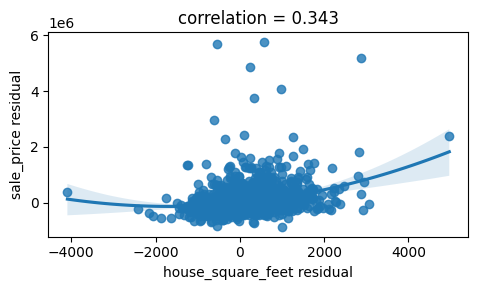

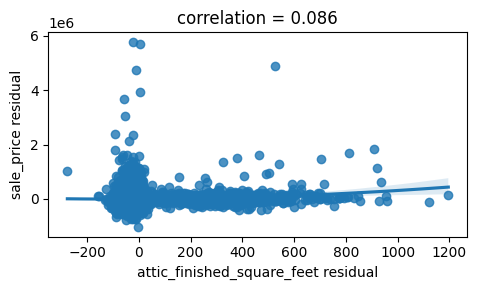

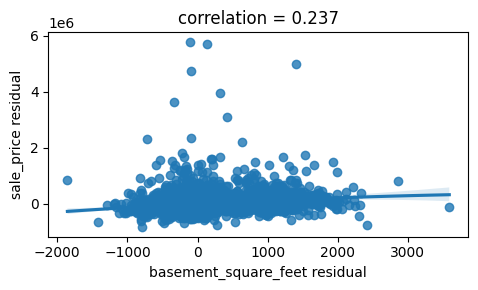

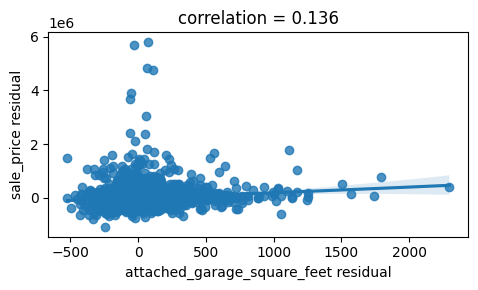

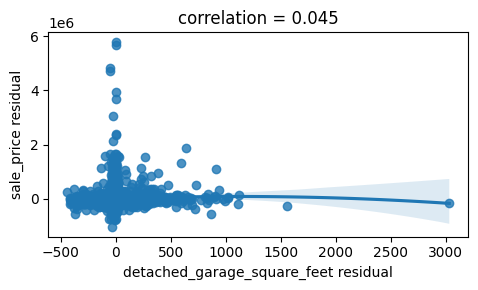

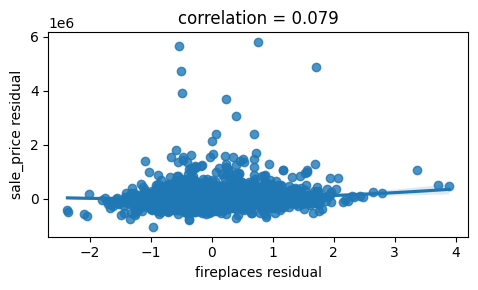

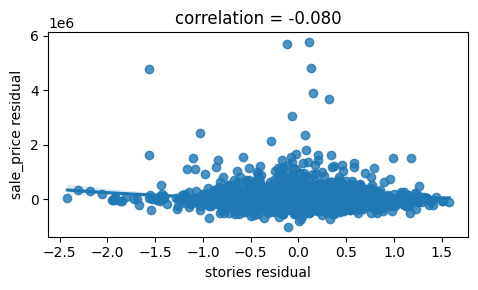

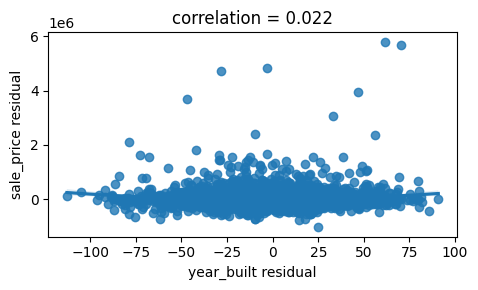

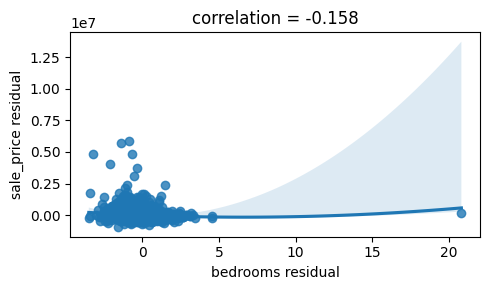

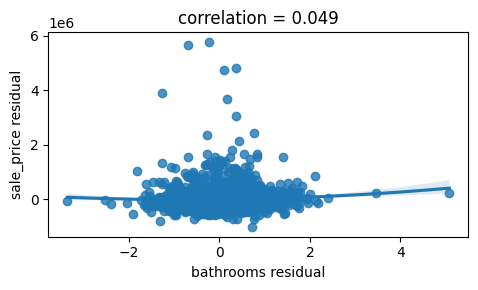

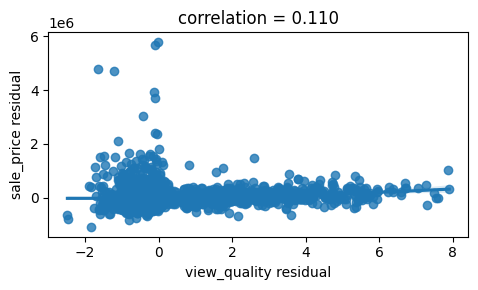

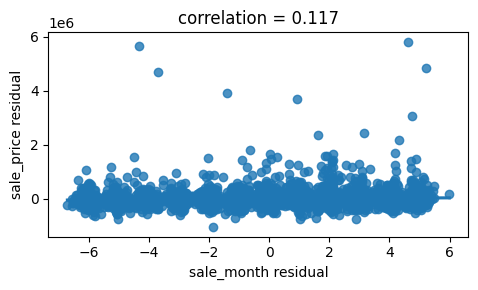

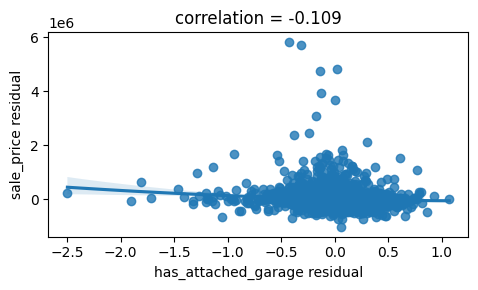

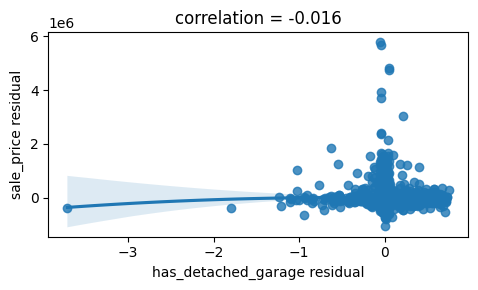

In [30]:
num_features_partial_plots = [c for c in num_features if c not in ['sale_year','house_age']] # Remove sale year and house age

for col in num_features_partial_plots: # Loop through numeric variables
    non_col = [c for c in num_features_partial_plots if c != col] # All columns except current one
    r_y = y_train - LinearRegression().fit(X_train[non_col], y_train).predict(X_train[non_col]) # Sale price - other feature prediction
    r_x = X_train[col] - LinearRegression().fit(X_train[non_col], X_train[col]).predict(X_train[non_col]) # Current feature - other feature prediction

    plt.figure(figsize=(5,3))
    sns.regplot(x=r_x, y=r_y, order=2) # Plot resid of x and resid of y, using order=2 to bend the line when its non-linear
    plt.title(f"correlation = {np.corrcoef(r_x, r_y)[0, 1]:.3f}")
    plt.xlabel(f"{col} residual")
    plt.ylabel("sale_price residual")
    plt.tight_layout()
    plt.show()


These partial correlation plots show how one specific numerical variable moves with sale price when the other features are held fixed. I used `order = 2` when plotting the correlation plots to more clearly show non-linearity. Most variables appear to be close to linear. The clearest non-linearity comes from house_square_feet, whose line of best fit is a U-shaped parabola that curves upward for the largest houses and slightly upward for the smallest houses. This means that for large houses each additional square foot adds more $ than it does for medium-sized houses, and that the largest houses are noticeably more expensive after controlling for the other features. Other plots that appear slightly non-linear are stories and fireplaces, but their bends are small and occur near the edges of their range where there are few observations. Although the bedrooms appears to be non-linear, its curve is driven by one outlier, and we can't deduce non-linearity from one point. I dropped sale_year because it is constant (all the sales are in 2020). I also dropped house_age because it represents the same information as year_built, but just in a different form.

## 6. Include transformations and interactions of your variables, and build a more complex model that reflects your ideas about how the features of the asset determine its value. Determine its RMSE and $R^2$ on the training and test sets. How does the more complex model your build compare to the simpler ones?

In [31]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

base_features = transform_encoded.drop(columns=['sale_price', 'log_price', 'sale_year', 'house_age']) # Base feature variables
print("Correlation between house age and year built:", round(transform_encoded['house_age'].corr(transform_encoded['year_built']),2))

# Square the non-linear features
expander = PolynomialFeatures(degree=2,include_bias=False) # Square
polynomials = ['house_square_feet', 'stories', 'fireplaces']

poly_array = expander.fit_transform(transform_encoded[polynomials]) # Array of squared features
poly_features = pd.DataFrame(poly_array, columns=expander.get_feature_names_out(), index=transform_encoded.index) # Transform array into dataframe

non_poly_features = [c for c in base_features.columns if c not in polynomials] # All features but the 3 squared features

# Define X and Y
X_complex = pd.concat([base_features[non_poly_features], poly_features], axis=1) # Add squared and non-squared features together
y_complex = transform_encoded['log_price'] # Transform price to log scale
complex_features = list(X_complex.columns)

# Split train/test
X_complex_train, X_complex_test, y_complex_train, y_complex_test = train_test_split(X_complex, y_complex, test_size = 0.2, random_state = 42) # 80/20 split
print('Train:', X_complex_train.shape, ' Test:', X_complex_test.shape)

# Build, fit, and predict model (scale features because of squared features)
sk_fit_complex = make_pipeline(StandardScaler(), LinearRegression()).fit(X_complex_train, y_complex_train)

y_complex_train_pred = sk_fit_complex.predict(X_complex_train[complex_features]) # Predict y on training set
y_complex_test_pred = sk_fit_complex.predict(X_complex_test[complex_features]) # Predict y on test set

print("Training set R-squared:", round(sk_fit_complex.score(X_complex_train[complex_features], y_complex_train), 4))
print("Training set RMSE (log units):", round(np.sqrt(mean_squared_error(y_complex_train, y_complex_train_pred)), 4))

print("Test set R-squared:", round(sk_fit_complex.score(X_complex_test[complex_features], y_complex_test), 4))
print("Test set RMSE (log units):", round(np.sqrt(mean_squared_error(y_complex_test, y_complex_test_pred)), 4))

Correlation between house age and year built: -1.0
Train: (13414, 43)  Test: (3354, 43)
Training set R-squared: 0.5107
Training set RMSE (log units): 0.2957
Test set R-squared: 0.4426
Test set RMSE (log units): 0.3275


In [32]:
from sklearn.metrics import r2_score

# Back to original units for comparison versus simple models
y_complex_train_dollars = np.exp(y_complex_train) # Exponent undos log
y_complex_test_dollars = np.exp(y_complex_test)

y_complex_train_pred_dollars = np.exp(y_complex_train_pred)
y_complex_test_pred_dollars = np.exp(y_complex_test_pred)

print("Training set R-squared:", round(r2_score(y_complex_train_dollars, y_complex_train_pred_dollars), 4))
print("Training set RMSE (dollar units):", round(np.sqrt(mean_squared_error(y_complex_train_dollars, y_complex_train_pred_dollars)), 2))

print("Test set R-squared:", round(r2_score(y_complex_test_dollars, y_complex_test_pred_dollars), 4))
print("Test set RMSE (dollar units):", round(np.sqrt(mean_squared_error(y_complex_test_dollars, y_complex_test_pred_dollars)), 2))

Training set R-squared: 0.5524
Training set RMSE (dollar units): 160231.36
Test set R-squared: 0.5385
Test set RMSE (dollar units): 150830.72


We based our complex model off the model using all features, since that was the most accurate of our simple models. Differences between our complex model and our simpler ones include:
1. We transformed `sale_price` using the log scale because prices are heavily right-skewed. The log scale helps to compress the larger prices.
2. We excluded `sale_year` because it is constant (all the sales are in 2020) and also `house_age` because it represents the same information as year_built (2020 - year built), but just in a different form. Dropping `house_age` accounted for the correlation between `house_age` and `year_built`, as their correlation was -1.
3. Based on our investigation of non-linear relationships between the features and sale price, we added degree-2 polynomial terms for `house_square_feet`, `stories` and `fireplaces`. These were the three variables that showed some curvature in our partial plots, so the squared terms let the model represent a curved relationship versus a linear line. The polynomial expansion also created terms that accounted for the interaction between these variables since `PolynomialFeatures` creates columns that represent the original features, their squares, and their products (for example, `house_square_feet` x `stories`). These products are what account for the interaction.
4. We then scaled all of our feature variables because the squared terms were on a larger scale than the non-squared variables.

As we discussed during EDA based on our correlation matrix, house size and amenities have the strongest relationships with sale price. House square footage has the highest correlation with price, followed by bathrooms, fireplaces, and attached garage size. This suggests that larger, better-equipped homes sell for more. In contrast, finished attic square footage and detached garage square footage have almost no linear relationship with price, while year built and bedrooms are only modestly related. Several predictors are also strongly correlated with each other. Square footage and bathrooms have a correlation of 0.74, and square footage is also related to bedrooms, stories, and year built, while year built and attached garage size correlate at 0.63.

We converted r-squared and RMSE back into dollars to compare the complex model with our simple models. Compared to our simple models, the complex model fits the training data slightly better than all three simple models with a training r-squared of 0.5524 and RMSE of 160,231, versus an r-squared of 0.5341 and RMSE of 163,480 for the all feature linear model (which had the highest r-squared and lowest RMSE of the simple models). However, it performs slightly worse than the all feature model on the testing data (r-squared of 0.5385 and RMSE of 150,831 compared to 0.5424 and 150,195 for the all-feature model). This suggests that our adjustments within the complex model, such as the log transformation, polynomial squaring, and interaction terms, may have fit patterns specific to the training data and did not improve predictions on new houses. Instead, it very slightly increased the difference between testing and training results, which could imply a small amount of overfitting, although it could also reflect the particular train/test split. As a result, the all-feature simple linear model ended up capturing most of the information from the features. The complex model still performed better than the numerical-only feature simple model or the categorical-only feature model.

# 7. Summarize your results from 1 to 6. Have you learned anything about overfitting and underfitting, or model selection?

### Summary of Results

* In Questions 1-3, we cleaned the data and performed some EDA. We found that sale price was very right-skewed, which informed our decision to use the log scale in our complex model. We also saw that square footage, bathrooms, and fireplaces had the strongest relationship with price. As a result, we knew these features would be important to our final model.
* In Question 4, the categorical-only model only had a test r-squared of 0.27. This means that the model only reduced squared prediction error by 27%. The numeric-only model performed better, with a test r-squared of 0.44, but it still had a lower r-squared than the all-feature model. Both of these models ignored important feature variables, so they both underfit the prediction. For example, the categorical-only model ignored the square footage of the home, which is a very import variable in determining size. The simple model with both numeric and categorical features had a test r squared of 0.54 and a test RMSE of about 150,195. Its training and test r squared were also within 0.008 of each other, which shows that it wasn't overfit, since it explained almost the same share of price variation on the new data as the training data.
* In Questions 5-6, we looked at partial plots and built a more complex model. The partial plots showed that `house_square_feet` had the most obvious non-linear relationship with `sale_price`, although `stories` and `fireplaces` has slightly non-linear relationships as well. As a result, we added squared terms for these three features, as well as transforming our target variable to the log scale, in our more complex model. The squared terms also created interaction features among those variables. After converting back to dollars, its test r-squared was 0.5385 and its test RMSE was about 150,831, which performed slightly worse than the all-feature simple model (0.5424 and 150,195), although not to a significant extent.

### Key Takeaways for Model Selection
1. The simple models that left out important features underfit the data, which taught us that we need to make sure the model includes the features that actually impact the target variable before trying to add any other complexity.
2. For this data, the all-feature linear model and complex model performed much more similarly than we would have expected. Adding squared terms, interactions, and a log transformation into our model didn't clearly improve sale price predictions, which shows that adding complexity doesn't always improve performance.
2. To check for overfitting, we compared training and testing scores. A large gap between them can be a warning sign of overfitting because it shows that the model is fitting noise in the training data.

# 8. Use the `sklearn.linear_model.Lasso` to regularize your model and select the most predictive features. Which does it select? What are the RMSE and $R^2$? We'll cover the Lasso later in detail in class.

In [33]:
from sklearn.linear_model import Lasso
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, r2_score

alpha_val = 0.01
lasso_pipeline = make_pipeline(StandardScaler(), Lasso(alpha=alpha_val, random_state=42))

#Fit the model on the complex training data
lasso_pipeline.fit(X_complex_train, y_complex_train)

# Predict on training and test sets
y_train_pred = lasso_pipeline.predict(X_complex_train)
y_test_pred = lasso_pipeline.predict(X_complex_test)

# Calculate RMSE and R^2 for both sets
train_rmse = np.sqrt(mean_squared_error(y_complex_train, y_train_pred))
test_rmse = np.sqrt(mean_squared_error(y_complex_test, y_test_pred))

train_r2 = r2_score(y_complex_train, y_train_pred)
test_r2 = r2_score(y_complex_test, y_test_pred)

print(f"Train RMSE (log): {train_rmse:.4f} | Train R^2: {train_r2:.4f}")
print(f"Test RMSE (log):  {test_rmse:.4f}  | Test R^2:  {test_r2:.4f}\n")

# Inspect the selected features (non-zero coefficients)
lasso_step = lasso_pipeline.named_steps['lasso']
feature_coefficients = pd.DataFrame({
    'Feature': X_complex_train.columns,
    'Coefficient': lasso_step.coef_
})

selected_features = feature_coefficients[feature_coefficients['Coefficient'] != 0]
dropped_features = feature_coefficients[feature_coefficients['Coefficient'] == 0]

print(f"Number of features selected: {len(selected_features)}")
print(f"Number of features dropped (coef = 0): {len(dropped_features)}\n")

print("Selected Features and Coefficients:")
display(selected_features.sort_values(by='Coefficient', ascending=False))

Train RMSE (log): 0.3011 | Train R^2: 0.4926
Test RMSE (log):  0.3314  | Test R^2:  0.4292

Number of features selected: 22
Number of features dropped (coef = 0): 21

Selected Features and Coefficients:


,Feature,Coefficient
34,house_square_feet,0.174561
1,basement_square_feet,0.066375
32,waterfront_type_WF Salt,0.063403
2,attached_garage_square_feet,0.040286
7,view_quality,0.039389
31,waterfront_type_WF Lake,0.038460
8,sale_month,0.032459
6,bathrooms,0.028288
13,hvac_description_Heat Pump,0.018281
36,fireplaces,0.015173


### Summary of Lasso Results

* **Features Selected:** The Lasso model with an alpha of 0.01 selected a subset of the most predictive features from the complex model, driving coefficients for less important or redundant features down to zero. Key features selected include:
  * Primary structural characteristics (such as house_square_feet and stories)
  * Essential amenities and site features (such as fireplaces, bathrooms, and view quality)
  * Specific high impact categorical variables (such as HVAC systems, roof covers, and waterfront classifications)
* **Model Performance:**
  * **Train Set:** R-squared of 0.4926 and RMSE of 0.3011.
  * **Test Set:** R-squared of 0.4292 and RMSE of 0.3314.
* **Takeaway:** Lasso  performed automated feature selection while maintaining a test performance comparable to the complex model. This helped to reduce overfitting by eliminating uninformative predictors.

### Summary of Lasso Results

- **Features Selected:** The Lasso model with an $\alpha$ of 0.01 performed automated feature selection on our complex model's feature set, driving coefficients for uninformative or redundant features down to zero while retaining the strongest predictors. Key features selected include:
  * Primary structural characteristics and polynomial/interaction terms (such as `house_square_feet`, `house_square_feet^2`, and `stories`)
  * Essential amenities and site features (such as `fireplaces`, `bathrooms`, and `view_quality`)
  * Specific high-impact categorical indicator variables (such as premium HVAC systems, roof covers, and waterfront classifications)
- **Model Performance:**
  * **Train Set:** $R^2$ of 0.4926 and RMSE of 0.3011 (log units).
  * **Test Set:** $R^2$ of 0.4292 and RMSE of 0.3314 (log units).
- **Takeaway:** Lasso successfully performed automated feature selection while maintaining a test performance comparable to the complex model, helping to reduce overfitting by eliminating noisy or uninformative predictors.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [34]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]